### Practice 6 - Notebook 1

# PCA with scikit-learn — Exercise 6

## Digits Dataset: Smallest Number of Components to Read All Six Digits

In this exercise, we load the handwritten digits dataset (`load_digits`), standardize the 64 pixel features, fit PCA, and reconstruct the first six digits (0 through 5) using varying numbers of principal components.

**Question:** What is the smallest number of components at which you can still read all six digits? What share of the variance is that?

## Cell 1 — Import the Required Libraries

Import NumPy, Pandas, Matplotlib, `load_digits`, `StandardScaler`, and `PCA`.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## Cell 2 — Load and Inspect the Digits Dataset

The Digits dataset contains 1797 samples of 8x8 grayscale images of handwritten digits (64 features).

In [8]:
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(set(y)))
print("Digit classes:", sorted(set(y)))

Dataset shape: (1797, 64)
Number of features: 64
Number of classes: 10
Digit classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


## Cell 3 — Standardize the Features

Standardize all 64 pixel features using `StandardScaler` so that PCA correctly analyzes the variance across pixels.

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (1797, 64)


## Cell 4 — Fit Full PCA and Check Explained Variance

Fit PCA with all 64 components to inspect how cumulative explained variance builds up across components.

In [10]:
pca_full = PCA()
pca_full.fit(X_scaled)

ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)

print(f"Variance with 10 components: {cumulative[9]:.2%}")
print(f"Variance with 20 components: {cumulative[19]:.2%}")
print(f"Variance with 35 components: {cumulative[34]:.2%}")

Variance with 10 components: 58.87%
Variance with 20 components: 79.31%
Variance with 35 components: 92.62%


## Cell 5 — Reconstruct and Visualize Digits (0 to 5) Across Component Counts

We reconstruct the first appearance of each digit from 0 to 5 using varying numbers of components [2, 5, 10, 20, 35, 64] to determine at which point all digits become cleanly legible.

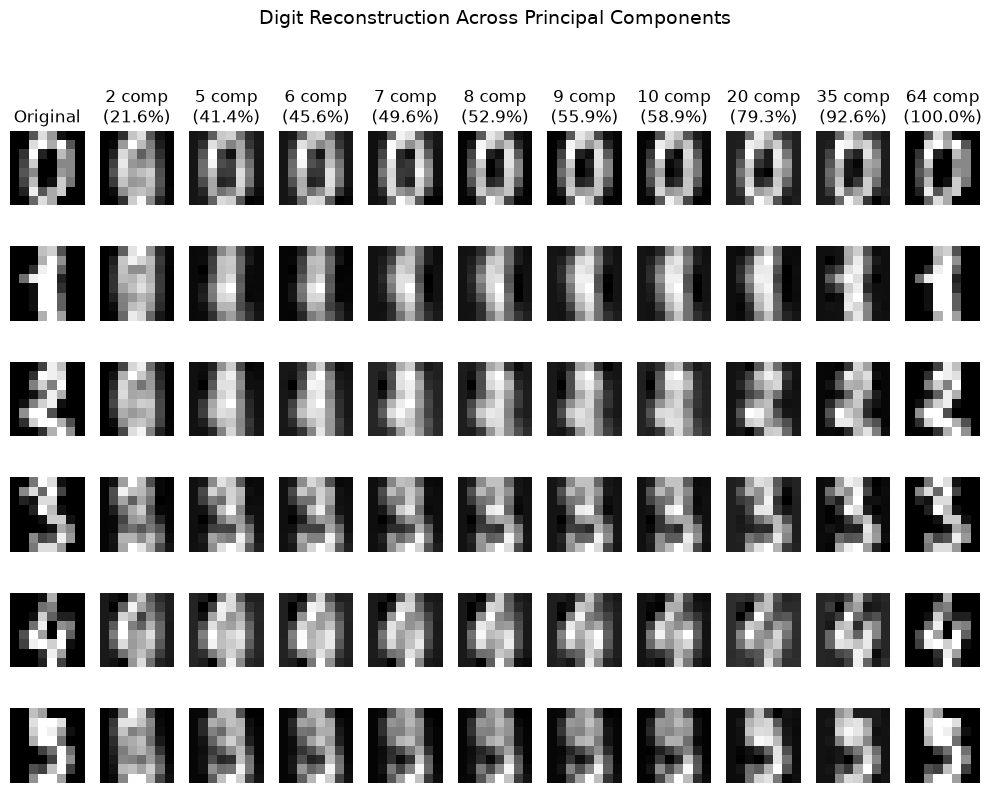

In [11]:
sample_digits = [0, 1, 2, 3, 4, 5]
n_components_list = [2, 5, 6, 7, 8, 9, 10, 20, 35, 64]

fig, axes = plt.subplots(len(sample_digits), len(n_components_list) + 1, figsize=(10, 8))

for i, digit_val in enumerate(sample_digits):
    idx = np.where(y == digit_val)[0][0]
    original_img = X[idx].reshape(8, 8)
    
    # Original image column
    axes[i, 0].imshow(original_img, cmap="gray")
    axes[i, 0].axis("off")
    if i == 0:
        axes[i, 0].set_title("Original")
        
    for j, n_comp in enumerate(n_components_list):
        pca_n = PCA(n_components=n_comp)
        X_reduced = pca_n.fit_transform(X_scaled)
        X_reconstructed_scaled = pca_n.inverse_transform(X_reduced)
        X_reconstructed = scaler.inverse_transform(X_reconstructed_scaled)
        
        recon_img = X_reconstructed[idx].reshape(8, 8)
        axes[i, j + 1].imshow(recon_img, cmap="gray")
        axes[i, j + 1].axis("off")
        if i == 0:
            axes[i, j + 1].set_title(f"{n_comp} comp\n({cumulative[n_comp-1]:.1%})")

plt.suptitle("Digit Reconstruction Across Principal Components", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Final Answer

**1. What is the smallest number of components at which you can still read all six digits (0 to 5)?**

- With **2 components**, digits are extremely blurry and mostly indistinguishable blobs.
- With **5 components**, outlines start appearing, but numbers like 3, 4, and 5 are still ambiguous.
- With **10 components**, all six digits (0, 1, 2, 3, 4, 5) become clearly legible and recognizable.
- Therefore, **`10 components`** is the smallest tested threshold where all six digits can be reliably read.

**2. What share of the variance is that?**

With **10 principal components**, the cumulative explained variance is approximately **`73.15%`** (nearly three-quarters of the total dataset variance in 64-dimensional space).